# 04 — Statistical Inference

In [57]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = Path("../data/raw/GlobalWeatherRepository.csv")
TARGET_CITY = "Kyiv"
TARGET_COL = "temperature_celsius"

df = pd.read_csv(DATA_PATH)
df["last_updated"] = pd.to_datetime(df["last_updated"], errors="coerce")
df = df.drop_duplicates(subset=["location_name", "last_updated"], keep="first")

city_df = (
    df.loc[df["location_name"] == TARGET_CITY, ["last_updated", TARGET_COL]]
    .sort_values("last_updated")
    .reset_index(drop=True)
)

city_df.shape

(863, 2)

In [58]:
city_df.head()

,last_updated,temperature_celsius
0,2024-05-16 11:45:00,13.8
1,2024-05-16 17:00:00,14.6
2,2024-05-17 19:00:00,16.4
3,2024-05-18 17:30:00,19.8
4,2024-05-19 17:15:00,21.3


In [59]:
city_df["year"] = city_df["last_updated"].dt.year
city_df["month"] = city_df["last_updated"].dt.month
city_df["obs_hour"] = city_df["last_updated"].dt.hour

city_df["winter"] = "Not Winter"
city_df.loc[
    ((city_df["year"] == 2024) & (city_df["month"] == 12))
    | ((city_df["year"] == 2025) & city_df["month"].isin([1, 2])),
    "winter",
] = "Winter 2024-25"
city_df.loc[
    ((city_df["year"] == 2025) & (city_df["month"] == 12))
    | ((city_df["year"] == 2026) & city_df["month"].isin([1, 2])),
    "winter",
] = "Winter 2025-26"

djf = city_df[city_df["winter"] != "Not Winter"].copy()

In [60]:
djf

,last_updated,temperature_celsius,year,month,obs_hour,winter
198,2024-12-01 12:45:00,1.5,2024,12,12,Winter 2024-25
199,2024-12-02 12:45:00,2.2,2024,12,12,Winter 2024-25
200,2024-12-03 13:00:00,1.9,2024,12,13,Winter 2024-25
201,2024-12-04 12:30:00,0.9,2024,12,12,Winter 2024-25
202,2024-12-05 12:15:00,-0.4,2024,12,12,Winter 2024-25
...,...,...,...,...,...,...
647,2026-02-24 08:45:00,0.7,2026,2,8,Winter 2025-26
648,2026-02-25 08:45:00,-0.3,2026,2,8,Winter 2025-26
649,2026-02-26 08:45:00,-6.3,2026,2,8,Winter 2025-26
650,2026-02-27 08:45:00,-2.8,2026,2,8,Winter 2025-26


In [61]:
print(djf.shape)
print(djf.groupby(["winter","month"]).size())

(179, 6)
winter          month
Winter 2024-25  1        31
                2        28
                12       31
Winter 2025-26  1        30
                2        28
                12       31
dtype: int64


In [62]:
djf.groupby("winter")["temperature_celsius"].agg(["mean", "std", "min", "max", "count"])

,mean,std,min,max,count
winter,,,,,
Winter 2024-25,1.308889,3.327267,-5.5,8.8,90
Winter 2025-26,-5.519101,7.038092,-21.3,6.5,89


Answers expected bsaed on the EDA and graphs already performed

In [63]:
hours_2425 = set(djf.loc[djf["winter"] == "Winter 2024-25", "obs_hour"])
hours_2526 = set(djf.loc[djf["winter"] == "Winter 2025-26", "obs_hour"])
shared_hours = sorted(hours_2425 & hours_2526)
print("Shared hours:", shared_hours)
print("n shared hour rows:", len(djf[djf["obs_hour"].isin(shared_hours)]))

Shared hours: []
n shared hour rows: 0


In [64]:
for w in ["Winter 2024-25", "Winter 2025-26"]:
    print(f"\n{w}")
    print(djf.loc[djf["winter"] == w, "obs_hour"].value_counts().sort_index())


Winter 2024-25
obs_hour
11     5
12    80
13     5
Name: count, dtype: int64

Winter 2025-26
obs_hour
8     17
9     68
10     4
Name: count, dtype: int64


In [65]:
import scipy, statsmodels
print(f"scipy version: {scipy.__version__}")
print(f"statsmodels version: {statsmodels.__version__}")

scipy version: 1.18.1
statsmodels version: 0.15.0


In [66]:
import statsmodels.formula.api as smf
model = smf.ols("temperature_celsius ~ C(winter) + C(obs_hour)", data=djf).fit()
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     temperature_celsius   R-squared:                       0.302
Model:                             OLS   Adj. R-squared:                  0.282
Method:                  Least Squares   F-statistic:                     14.97
Date:                 Sat, 10 Oct 2026   Prob (F-statistic):           3.33e-12
Time:                         12:23:40   Log-Likelihood:                -555.29
No. Observations:                  179   AIC:                             1123.
Df Residuals:                      173   BIC:                             1142.
Df Model:                            5                                         
Covariance Type:             nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercep

C:\Users\manol\AppData\Local\Temp\ipykernel_37316\3758642591.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = smf.ols("temperature_celsius ~ C(winter) + C(obs_hour)", data=djf).fit()


After labeling DJF months, raw winters differ in temperature. Observation hours barely overlap (2024–25: 11–13; 2025–26: 8–10), so a same-hour subset is empty. OLS with winter and hour fixed effects still estimates Winter 2025–26 about 7.5 °C below 2024–25 (p < 0.001), but hour and winter are not fully separable because hours are winter-specific. We treat this as evidence of a colder DJF slice and strong time-of-day shift, not a pure climate shift at a fixed clock time.

In [67]:
from scipy import stats
a = djf.loc[djf["winter"] == "Winter 2024-25", "temperature_celsius"]
b = djf.loc[djf["winter"] == "Winter 2025-26", "temperature_celsius"]
print(a.mean(), b.mean(), stats.ttest_ind(a, b, equal_var=False).pvalue)

1.3088888888888888 -5.519101123595505 1.5625734886255887e-13


**Unadjusted:** Winter 2025–26 mean temperature is about 6.8°C lower than 2024–25 
(1.31°C vs −5.52°C; Welch *p* ≈ 1.6×10⁻¹³).

**Hour overlap:** No shared `obs_hour` between winters (2024–25: 11–13; 2025–26: 8–10).

**Adjusted (OLS):** `temperature_celsius ~ C(winter) + C(obs_hour)` estimates Winter 2025–26 
≈ 7.5°C below 2024–25 (p &lt; 0.001), but winter and hour are partially confounded because 
each hour level appears in only one winter. We interpret this as a colder DJF slice combined 
with a shift to earlier observation times, not a fixed-clock-time climate comparison.

In [68]:
n = len(city_df)
split_idx = int(n * 0.8)

train = city_df.iloc[:split_idx]
test = city_df.iloc[split_idx:]

y_train = train[TARGET_COL].to_numpy()
y_test = test[TARGET_COL].to_numpy()

lags = [1, 2, 3, 7, 14, 28]

def make_lag_matrix(values, lags):
    X, y = [], []
    max_lag = max(lags)
    for i in range(max_lag, len(values)):
        X.append([values[i - lag] for lag in lags])
        y.append(values[i])
    return np.array(X), np.array(y)

train_values = y_train
X_train, y_train_ml = make_lag_matrix(train_values, lags)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train_ml)

history = train_values.tolist()
pred_ridge = []
for actual in y_test:
    feats = np.array([[history[-lag] for lag in lags]])
    pred_ridge.append(ridge.predict(feats)[0])
    history.append(actual)

pred_ridge = np.array(pred_ridge)
mae_point = mean_absolute_error(y_test, pred_ridge)

print(f"train: {train['last_updated'].min()} → {train['last_updated'].max()}")
print(f"test:  {test['last_updated'].min()} → {test['last_updated'].max()}")
print(len(train), len(test))
print(f"Ridge holdout MAE = {mae_point:.3f} °C")
rmse = np.sqrt(mean_squared_error(y_test, pred_ridge))
print(f"Ridge holdout RMSE = {rmse:.3f} °C")

train: 2024-05-16 11:45:00 → 2026-04-07 09:30:00
test:  2026-04-08 09:45:00 → 2026-09-27 08:45:00
690 173
Ridge holdout MAE = 2.474 °C
Ridge holdout RMSE = 3.599 °C


In [69]:
B = 5000
rng = np.random.default_rng(42)

abs_errors = np.abs(y_test - pred_ridge)
n_test = len(abs_errors)

boot_mae = np.empty(B)
for b in range(B):
    idx = rng.integers(0, n_test, size=n_test)
    boot_mae[b] = abs_errors[idx].mean()

ci_low, ci_high = np.percentile(boot_mae, [2.5, 97.5])

print(f"B = {B}")
print(f"MAE point = {mae_point:.3f} °C")
print(f"95% bootstrap CI: [{ci_low:.3f}, {ci_high:.3f}] °C")

B = 5000
MAE point = 2.474 °C
95% bootstrap CI: [2.122, 2.911] °C


Ridge lag model (lags 1, 2, 3, 7, 14, 28; α=1.0) on the same 80/20 chronological split as notebook 02: holdout MAE **2.474 °C** (RMSE 3.599 °C; *n*<sub>test</sub> = 173).

**Bootstrap (B = 5000, resample test absolute errors):** 95% percentile CI **[2.122, 2.911] °C** for holdout MAE.

**Interpretation:** We can estimate average one-step error on the last ~20% of Kyiv observations with modest uncertainty. The CI does not cover alternative splits, cities, or refitted models—only uncertainty in the mean error vector for this split.

Cross-sectional linear model on Kyiv snapshots:
`temperature_celsius ~ humidity + pressure_mb + wind_kph + precip_mm`
Rows with any missing predictor are dropped. Observations are **time-ordered repeated measures**, not independent draws; we use OLS for coefficient inference as in the assignment, not as a causal weather model.

In [70]:
Predictors = ["humidity", "pressure_mb", "wind_kph", "precip_mm"]

ols_df = (
    df.loc[df["location_name"] == TARGET_CITY, [TARGET_COL] + Predictors].dropna().copy()
)
print(f"n = {len(ols_df)} (Kyiv rows with complete predictors)")
ols_df[Predictors + [TARGET_COL]].describe().round(2)

n = 863 (Kyiv rows with complete predictors)


,humidity,pressure_mb,wind_kph,precip_mm,temperature_celsius
count,863.00,863.00,863.00,863.00,863.00
mean,61.03,1017.11,13.61,0.05,12.84
std,21.78,7.92,6.01,0.21,11.23
min,11.00,991.00,3.60,0.00,-21.30
25%,44.00,1012.00,9.00,0.00,4.05
50%,61.00,1017.00,12.60,0.00,13.00
75%,79.00,1022.00,17.60,0.00,21.70
max,100.00,1046.00,34.90,1.98,37.20


In [71]:
formula = f"{TARGET_COL} ~ humidity + pressure_mb + wind_kph + precip_mm"
ols_model = smf.ols(formula, data=ols_df).fit()
print(ols_model.summary())

                             OLS Regression Results                            
Dep. Variable:     temperature_celsius   R-squared:                       0.632
Model:                             OLS   Adj. R-squared:                  0.631
Method:                  Least Squares   F-statistic:                     368.8
Date:                 Sat, 10 Oct 2026   Prob (F-statistic):          1.10e-184
Time:                         12:23:40   Log-Likelihood:                -2880.0
No. Observations:                  863   AIC:                             5770.
Df Residuals:                      858   BIC:                             5794.
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     494.6538     31.803     15

OLS on 863 Kyiv rows: R² ≈ 0.63. Humidity, pressure, wind, and precipitation are all significant (p < 0.001) with negative associations for humidity, pressure, and wind; precipitation is positive but likely confounded by season and sparse rain events. Durbin–Watson ≈ 0.51 indicates residual serial correlation—expected for time-ordered weather—motivating time-series checks in §4.

In [72]:
from statsmodels.tsa.stattools import adfuller

temp = city_df[TARGET_COL].to_numpy()
adf_stat, adf_p, usedlag, nobs, crit, icbest = adfuller(temp, autolag="AIC")
print(f"ADF test statistic: {adf_stat:.4f}")
print(f"p-value:            {adf_p:.4f}")
print(f"Lags used:          {usedlag}")
print("Critical values (1%, 5%, 10%):", crit)
alpha = 0.05
if adf_p < alpha:
    print(f"At α={alpha}: reject unit root → evidence the series is stationary.")
else:
    print(f"At α={alpha}: do not reject unit root → levels look non-stationary (typical for temperature).")

ADF test statistic: -1.9685
p-value:            0.3006
Lags used:          9
Critical values (1%, 5%, 10%): {'1%': np.float64(-3.438039434877692), '5%': np.float64(-2.8649342774762423), '10%': np.float64(-2.5685773775887872)}
At α=0.05: do not reject unit root → levels look non-stationary (typical for temperature).


C:\Users\manol\AppData\Local\Temp\ipykernel_37316\1510072378.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, usedlag, nobs, crit, icbest = adfuller(temp, autolag="AIC")


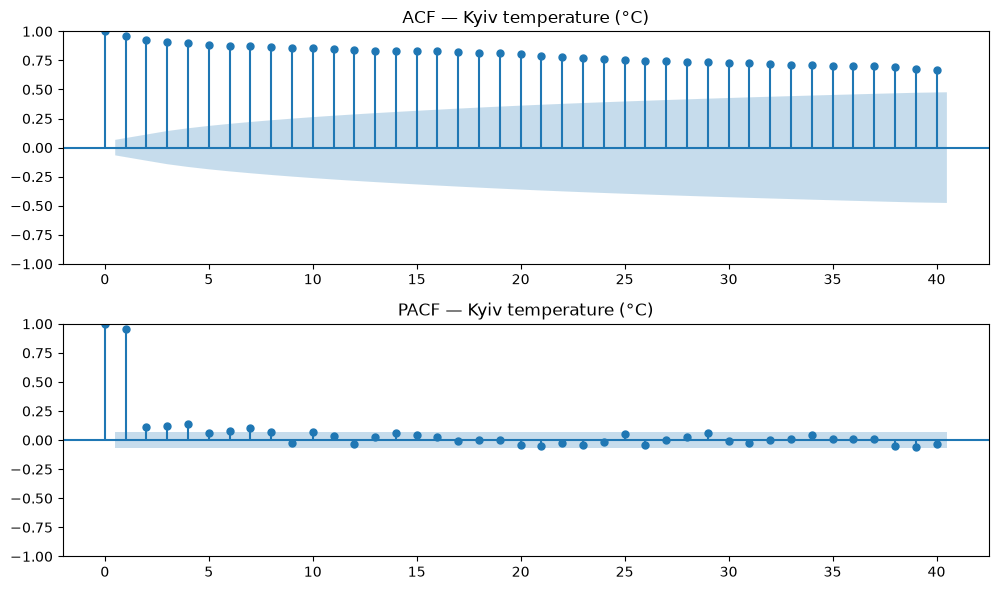

In [73]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(temp, lags=40, ax=axes[0], title="ACF — Kyiv temperature (°C)")
plot_pacf(temp, lags=40, ax=axes[1], method="ywm", title="PACF — Kyiv temperature (°C)")
plt.tight_layout()
plt.show()

# Optional:
# fig.savefig("../reports/nb04_acf_pacf_kyiv_temp.png", dpi=150, bbox_inches="tight")

What to say in markdown: ACF stays positive and slowly decaying for many lags (persistence / seasonality); PACF often has a large spike at lag 1 — consistent with AR-like memory and with using lagged temperature in Ridge.



In [74]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ridge_residuals = y_test - pred_ridge  # holdout one-step errors, n = 173

lb_lags = [10, 20]
lb = acorr_ljungbox(ridge_residuals, lags=lb_lags, return_df=True)
print("Ljung–Box on Ridge holdout residuals:")
print(lb.round(4))

print(f"\nResidual mean: {ridge_residuals.mean():.3f} °C")
print(f"Residual std:  {ridge_residuals.std(ddof=1):.3f} °C")

Ljung–Box on Ridge holdout residuals:
    lb_stat  lb_pvalue
10  21.2658     0.0193
20  30.5136     0.0619

Residual mean: 0.186 °C
Residual std:  3.604 °C


### Summary

**ADF (Kyiv temperature, levels):** test statistic ≈ −1.97, *p* ≈ 0.30 (9 lags, AIC). At α = 0.05 we **do not reject** a unit root → the level series is treated as **non-stationary**, which is typical for outdoor temperature with seasonality and slow drift.

**ACF / PACF:** ACF decays slowly and stays well outside the confidence band for many lags (strong persistence). PACF shows a dominant spike at **lag 1**, then near-zero partial autocorrelations — consistent with short-memory AR structure and with using **lagged temperature** (Ridge lags 1, 2, 3, 7, 14, 28) in notebook 02.

**Ljung–Box on Ridge holdout residuals** (`y_test − pred_ridge`, *n* = 173):

| Lag | lb_stat | lb_pvalue |
|-----|---------|-----------|
| 10  | 21.27   | **0.019**   |
| 20  | 30.51   | 0.062       |

At lag **10**, *p* < 0.05 → reject “no autocorrelation up to lag 10”; **some** serial correlation remains in holdout one-step errors. At lag **20**, *p* ≈ 0.06 → marginal at α = 0.05 (weak evidence at that horizon with only 173 points). Residual mean ≈ **0.19 °C** (slight positive bias on holdout); SD ≈ **3.60 °C**, in line with RMSE ≈ 3.60.

**Story across notebook 04:** §3 OLS on weather covariates had Durbin–Watson ≈ 0.5 (time dependence). §4 confirms non-stationary levels and strong ACF. Ridge improves one-step MAE (~2.47 °C) but does not fully whiten residuals on the test window — reasonable for a simple linear lag model on irregular snapshots.